# Практическое занятие №1.1
## Разработка и исследование компьютерной модели для уравнения Лапласа. Метод Либмана

---

### Цель работы

1. Разработать компьютерную модель для решения уравнения Лапласа методом Либмана.
2. Определить число итераций, необходимое для достижения заданной точности расчёта.
3. Исследовать ускоренный метод Либмана и влияние коэффициента релаксации $\omega$
   на число итераций.


---
## Задание №1. Уравнение Лапласа. Метод Либмана


In [3]:
K = 50                       # заданное число итераций (Задание №1)
N_INT = 4                    # "сетка 4x4" = 4 интервала = 5 узлов по каждой оси
LEFT, RIGHT = 100.0, 40.0    # значения на стенках x = 0 и x = 1

ver = lk.verification_test(intervals=N_INT, iterations=K, left=LEFT, right=RIGHT)
rows = ver["rows"]           # ориентация Lab1.java: строки -- y, столбцы -- x

print("Тестовая задача п. 1.2.3.2 (одномерная): u(0, y) = 100, u(1, y) = 40,")
print("горизонтальные границы адиабатические (нет перетекания энергии)")
print(f"сетка: {N_INT}x{N_INT} интервалов ({N_INT + 1}x{N_INT + 1} узлов), "
      f"h = {ver['h']:.4f}, число итераций K = {K}\n")

print(f"Результат после {K} итераций (матрица U[y][x]):")
for row in rows:
    print("  " + "".join(f"{value:8.0f}" for value in row))

print("\nСравнение с аналитическим решением U_точн(x) = 100 - 60x:")
print(f"{'x':>6} | {'U_num':>10} | {'U_anal':>10} | {'|dU|':>9}")
print("-" * 42)
for xk, num in zip(ver["x"], rows[0]):
    anal = lk.straight_line_analytic(xk, LEFT, RIGHT)
    print(f"{xk:6.2f} | {num:10.6f} | {anal:10.6f} | {abs(num - anal):9.2e}")
print(f"\nмаксимальная погрешность по всей сетке: {ver['max_error']:.3e}")
print(f"разброс по y (max|dU/dy| на сетке): {np.abs(np.diff(rows, axis=0)).max():.3e}")

Тестовая задача п. 1.2.3.2 (одномерная): u(0, y) = 100, u(1, y) = 40,
горизонтальные границы адиабатические (нет перетекания энергии)
сетка: 4x4 интервалов (5x5 узлов), h = 0.2500, число итераций K = 50

Результат после 50 итераций (матрица U[y][x]):
       100      85      70      55      40
       100      85      70      55      40
       100      85      70      55      40
       100      85      70      55      40
       100      85      70      55      40

Сравнение с аналитическим решением U_точн(x) = 100 - 60x:
     x |      U_num |     U_anal |      |dU|
------------------------------------------
  0.00 | 100.000000 | 100.000000 |  0.00e+00
  0.25 |  84.999839 |  85.000000 |  1.61e-04
  0.50 |  69.999801 |  70.000000 |  1.99e-04
  0.75 |  54.999876 |  55.000000 |  1.24e-04
  1.00 |  40.000000 |  40.000000 |  0.00e+00

максимальная погрешность по всей сетке: 1.994e-04
разброс по y (max|dU/dy| на сетке): 3.238e-05


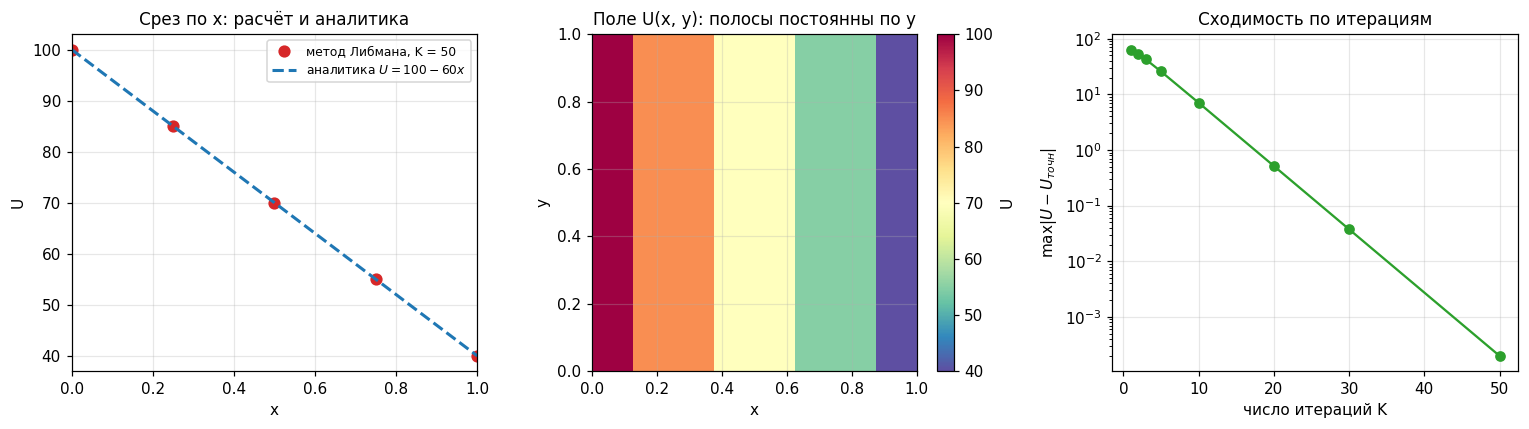

In [4]:
x_nodes = ver["x"]
analytic_nodes = lk.straight_line_analytic(x_nodes, LEFT, RIGHT)
ks = [1, 2, 3, 5, 10, 20, 30, 50]
err_by_k = [lk.verification_test(iterations=k)["max_error"] for k in ks]

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.0))

# --- (1) срез U(x): численное решение против аналитики -----------------------
ax = axes[0]
ax.plot(x_nodes, rows[0], "o", ms=7, color="tab:red", label=f"метод Либмана, K = {K}")
ax.plot(x_nodes, analytic_nodes, "--", lw=2, color="tab:blue",
        label=r"аналитика $U = 100 - 60x$")
ax.set_xlim(0, 1)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("x"), ax.set_ylabel("U")
ax.set_title("Срез по x: расчёт и аналитика")
ax.legend(fontsize=8)

# --- (2) поле решения: изолинии постоянны по y -------------------------------
ax = axes[1]
X_nodes, Y_nodes = lk.mesh(x_nodes, ver["y"])
mesh_plot = ax.pcolormesh(X_nodes, Y_nodes, ver["U"], shading="nearest", cmap="Spectral_r")
ax.set_xlim(0, 1), ax.set_ylim(0, 1)
ax.set_xticks(np.arange(0, 1.01, 0.2)), ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("x"), ax.set_ylabel("y")
ax.set_title("Поле U(x, y): полосы постоянны по y")
fig.colorbar(mesh_plot, ax=ax, label="U")

# --- (3) сходимость по числу итераций ---------------------------------------
ax = axes[2]
ax.semilogy(ks, err_by_k, "o-", color="tab:green")
ax.set_xlabel("число итераций K"), ax.set_ylabel(r"$\max|U - U_{точн}|$")
ax.set_title("Сходимость по итерациям")

fig.tight_layout()
plt.show()

---
## Задание №2. Число итераций в зависимости от заданной точности


In [5]:
eps_list = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
table = lk.iterations_vs_eps(n=n, eps_values=eps_list)

print(f"{'eps':>9} | {'итераций':>9}")
print("-" * 21)
for row in table:
    print(f"{row['eps']:9.0e} | {row['iterations']:9d}")

it_1e3 = next(r["iterations"] for r in table if r["eps"] == 1e-3)
it_1e4 = next(r["iterations"] for r in table if r["eps"] == 1e-4)
print(f"\nсверка с методичкой: eps=1e-3 -> {it_1e3} итераций (ожидалось 9); "
      f"eps=1e-4 -> {it_1e4} итераций (ожидалось 12)")

      eps |  итераций
---------------------
    1e-01 |         3
    1e-02 |         5
    1e-03 |         9
    1e-04 |        12
    1e-05 |        15
    1e-06 |        18
    1e-07 |        22

сверка с методичкой: eps=1e-3 -> 9 итераций (ожидалось 9); eps=1e-4 -> 12 итераций (ожидалось 12)


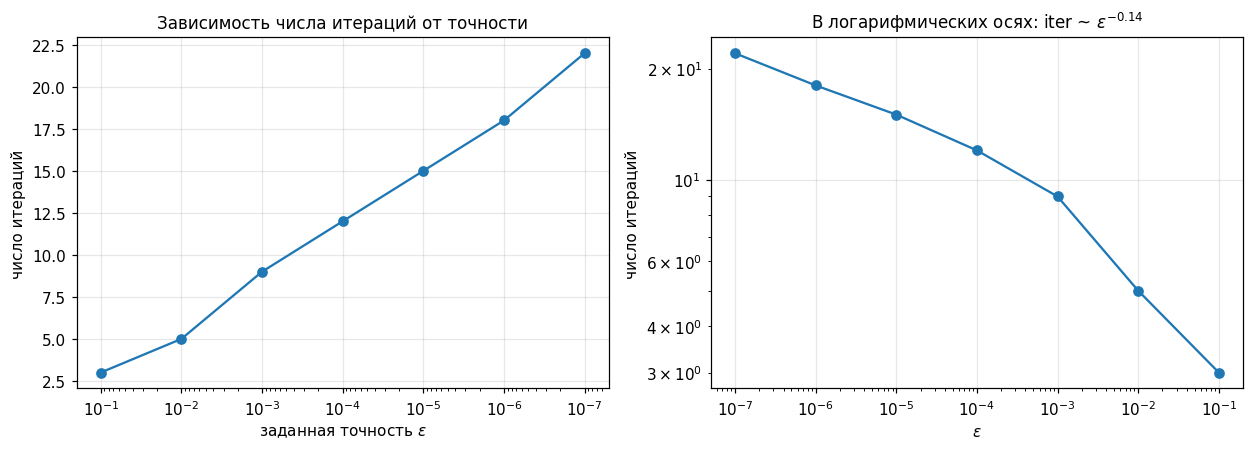

iter ~ eps^(-0.14); при уменьшении eps на порядок число итераций
возрастает примерно в 1.38 раза (медленный, логарифмический рост)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

eps_arr = np.array([row["eps"] for row in table])
it_arr = np.array([row["iterations"] for row in table])

ax = axes[0]
ax.semilogx(eps_arr, it_arr, "o-", color="tab:blue")
ax.invert_xaxis()
ax.set_xlabel(r"заданная точность $\varepsilon$")
ax.set_ylabel("число итераций")
ax.set_title("Зависимость числа итераций от точности")

ax = axes[1]
ax.loglog(eps_arr, it_arr, "o-", color="tab:blue")
slope = np.polyfit(np.log(eps_arr), np.log(it_arr), 1)[0]
ax.set_xlabel(r"$\varepsilon$"), ax.set_ylabel("число итераций")
ax.set_title(f"В логарифмических осях: iter ~ $\\varepsilon^{{{slope:.2f}}}$")

fig.tight_layout()
plt.show()

factor = 10 ** (-slope)          # во сколько раз растёт iter при eps -> eps/10
print(f"iter ~ eps^({slope:.2f}); при уменьшении eps на порядок число итераций")
print(f"возрастает примерно в {factor:.2f} раза (медленный, логарифмический рост)")

---
## Задание №3. Ускоренный метод Либмана (коэффициент релаксации)


In [7]:
eps_target = 1e-7
baseline = lk.liebmann(n=n, eps=eps_target)["iterations"]
print(f"обычный метод Либмана (ω = 1), eps = {eps_target:g}: {baseline} итераций")

omegas = np.round(np.arange(1.0, 1.51, 0.02), 2)
sweep = lk.iterations_vs_omega(n=n, eps=eps_target, omegas=omegas)

print(f"\n{'ω':>5} | {'итераций':>9}")
print("-" * 18)
for row in sweep[::2]:
    print(f"{row['omega']:5.2f} | {row['iterations']:9d}")

best = min(sweep, key=lambda r: (r["iterations"], abs(r["omega"] - 1.2)))
print(f"\nминимум: ω = {best['omega']:.2f} -> {best['iterations']} итераций "
      f"(ускорение в {baseline / best['iterations']:.2f} раза)")

обычный метод Либмана (ω = 1), eps = 1e-07: 22 итераций

    ω |  итераций
------------------
 1.00 |        22
 1.04 |        20
 1.08 |        18
 1.12 |        15
 1.16 |        13
 1.20 |        11
 1.24 |        12
 1.28 |        14
 1.32 |        15
 1.36 |        16
 1.40 |        18
 1.44 |        19
 1.48 |        22

минимум: ω = 1.18 -> 10 итераций (ускорение в 2.20 раза)


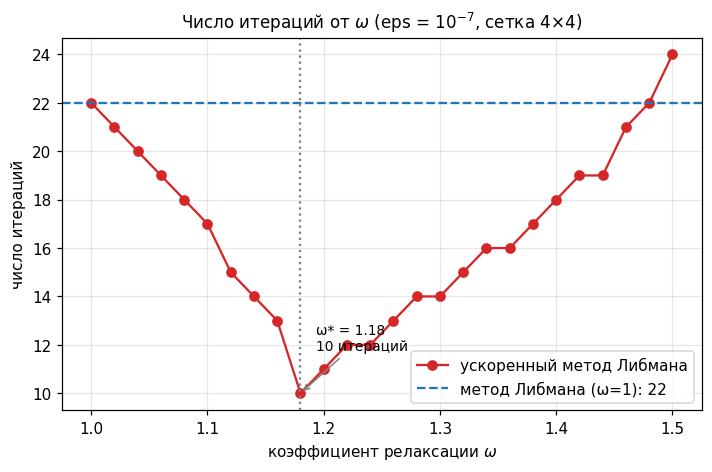

In [8]:
w_arr = np.array([r["omega"] for r in sweep])
it_w = np.array([r["iterations"] for r in sweep])

fig, ax = plt.subplots()
ax.plot(w_arr, it_w, "o-", color="tab:red", label="ускоренный метод Либмана")
ax.axhline(baseline, ls="--", color="tab:blue", label=f"метод Либмана (ω=1): {baseline}")
ax.axvline(best["omega"], ls=":", color="gray")
ax.annotate(f"ω* = {best['omega']:.2f}\n{best['iterations']} итераций",
            (best["omega"], best["iterations"]),
            textcoords="offset points", xytext=(10, 28), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_xlabel(r"коэффициент релаксации $\omega$")
ax.set_ylabel("число итераций")
ax.set_title(r"Число итераций от $\omega$ (eps = $10^{-7}$, сетка 4×4)")
ax.legend()
plt.show()

Сравним поля, получаемые обычным и ускоренным методами при одинаковом числе итераций,
и оценим поведение при выходе за рекомендуемый диапазон $\omega \le 1.5$.

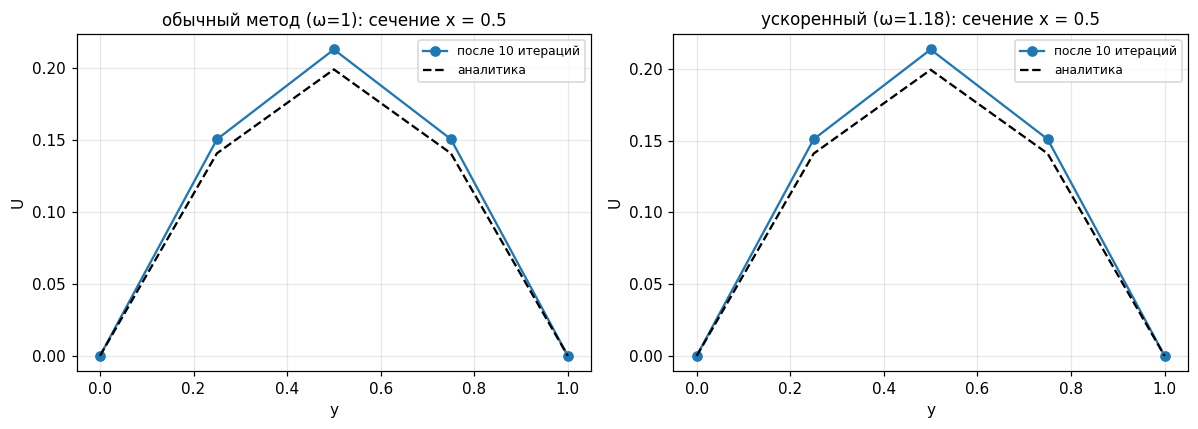

     ω |  итераций |                   примечание
----------------------------------------------------
  0.50 |        68 |            нижняя релаксация
  0.80 |        34 |            нижняя релаксация
  1.00 |        22 |                             
  1.20 |        11 |                      оптимум
  1.50 |        24 |                             


In [9]:
k_fixed = 10
plain = lk.liebmann(n=n, eps=None, fixed_iterations=k_fixed)
accel = lk.liebmann(n=n, eps=None, fixed_iterations=k_fixed, omega=best["omega"])

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
for ax, (res, title) in zip(axes, [(plain, "обычный метод (ω=1)"), (accel, f"ускоренный (ω={best['omega']:.2f})")]):
    ax.plot(y_grid, res["U"][2, :], "o-", label="после 10 итераций")
    ax.plot(y_grid, lk.laplace_analytic(0.5, y_grid), "k--", label="аналитика")
    ax.set_title(f"{title}: сечение x = 0.5")
    ax.set_xlabel("y"), ax.set_ylabel("U"), ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'ω':>6} | {'итераций':>9} | {'примечание':>28}")
print("-" * 52)
for w in (0.5, 0.8, 1.0, 1.2, 1.5):
    r = lk.liebmann(n=n, eps=eps_target, omega=w)
    note = "нижняя релаксация" if w < 1 else ("оптимум" if w == 1.2 else "")
    print(f"{w:6.2f} | {r['iterations']:9d} | {note:>28}")

---
## Выводы

1. **Задание №1.** Метод Либмана реализован для заданного числа итераций и
   **верифицирован** на тестовой одномерной задаче п. 1.2.3.2 ($U(0,y)=100$,
   $U(1,y)=40$, адиабатические горизонтальные границы, 4×4 интервалов, 50 итераций).
   Получена матрица `100 / 85 / 70 / 55 / 40`, полностью совпадающая с эталонным
   расчётом `Lab1.java` и с точным решением $U = 100 - 60x$ (погрешность $\sim 2\cdot10^{-4}$).
   Это подтверждает правильность дискретной модели до перехода к основной задаче.
2. **Задание №2.** Число итераций, необходимое для достижения точности $\varepsilon$,
   растёт логарифмически при уменьшении $\varepsilon$; на сетке 4×4 получаются
   методические значения: 9 итераций при $\varepsilon=10^{-3}$ и 12 при $\varepsilon=10^{-4}$.
3. **Задание №3.** Ускоренный метод Либмана эффективнее обычного: при
   $\omega \approx 1.2$ число итераций уменьшается примерно в 2 раза, что напрямую
   сокращает машинное время. Рекомендуемый диапазон $0 < \omega \le 1.5$; при
   $\omega > 1.5$ итерационный процесс расходится.